# Signal and Model Discovery

Volatility forecasting (GARCH, Random Forest), pair cointegration and OU spreads, HMM regime detection.


In [1]:
from pathlib import Path
import sys

project_root = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()

if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

# Load IPython autoreload so edits in src/ are picked up after rerunning cells.
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np  # Finite checks for OU visualization.
import pandas as pd

import src.models.volatility as vol_modeling  # Import as a module so autoreload updates the functions.
from src.models.ou import (
    compute_spread_zscore,
    estimate_ou_parameters,
    estimate_ou_parameters_exact_discrete,
    run_cointegration_test,
)
from src.models.regime import build_regime_features, fit_hmm_regime_model, infer_regimes, summarize_regimes
from src.utils.config import DATA_CONFIG
from src.utils.data_loader import build_market_data_bundle, build_spread, make_volatility_features


## Load market data

Shared ETF universe; prices, log returns, and rolling realized volatility.


In [3]:
market_data = build_market_data_bundle()
prices = market_data.prices  # Keep the price table in a short variable name.
returns = market_data.log_returns
realized_vol = market_data.realized_volatility

prices.tail()


,EEM,EFA,FXE,GLD,SPY,TLT,USO,UUP
Date,,,,,,,,
2025-12-23,54.310001,96.290001,108.441269,413.640015,686.086304,86.213600,70.300003,26.940001
2025-12-24,54.419998,96.410004,108.341576,411.929993,688.499695,86.735809,70.199997,26.950001
2025-12-26,54.799999,96.570000,108.361519,416.739990,688.429871,86.450058,68.480003,26.969999
2025-12-29,54.660000,96.279999,108.321632,398.600006,685.976562,86.775223,69.610001,26.980000
2025-12-30,54.880001,96.440002,108.072395,398.890015,685.138916,86.568298,69.739998,27.049999


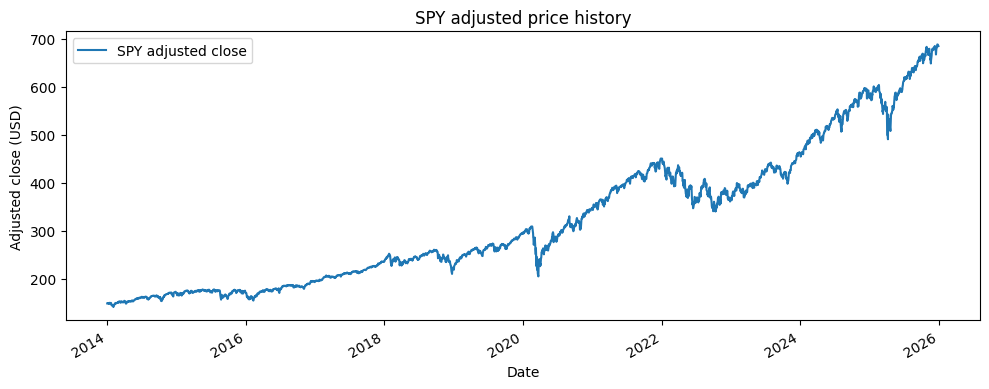

In [4]:
benchmark_prices = prices[DATA_CONFIG.benchmark_symbol]
benchmark_returns = returns[DATA_CONFIG.benchmark_symbol]
benchmark_realized_vol = realized_vol[DATA_CONFIG.benchmark_symbol].reindex(benchmark_returns.index)

ax_price = benchmark_prices.plot(figsize=(10, 4), title="SPY adjusted price history", label="SPY adjusted close")
ax_price.set_xlabel("Date")
ax_price.set_ylabel("Adjusted close (USD)")
ax_price.legend(loc="best")
plt.tight_layout()
plt.show()


## Step 2 - Forecast volatility

We compare two viewpoints:
- `GARCH(1,1)` says volatility clusters because today depends on yesterday's shock and yesterday's volatility.
- `RandomForest` says volatility may depend on several nonlinear lagged features.

At this stage we only judge forecast quality, not trading performance.

In [5]:
volatility_features = make_volatility_features(benchmark_returns, benchmark_realized_vol)  # Build lagged predictors and the next-period target.
train_features, test_features = vol_modeling.split_train_test(volatility_features)

rf_model = vol_modeling.fit_random_forest_volatility_model(train_features)
rf_prediction = vol_modeling.predict_random_forest_volatility(rf_model, test_features)
rf_metrics = vol_modeling.evaluate_forecasts(test_features["target_volatility"], rf_prediction)

pd.Series(rf_metrics, name="random_forest").to_frame()


,random_forest
mse,0.000188
mae,0.008328
correlation,0.985464


In [6]:
garch_fit = vol_modeling.fit_garch_model(benchmark_returns)  # Fit the GARCH model on the same benchmark return stream.
garch_volatility = vol_modeling.extract_garch_conditional_volatility(garch_fit, benchmark_returns.index)
garch_target = benchmark_realized_vol.reindex(garch_volatility.index)  # Align realized volatility with the GARCH output.
garch_metrics = vol_modeling.evaluate_forecasts(garch_target, garch_volatility)  # Evaluate how close GARCH is to realized volatility.

comparison = pd.DataFrame([rf_metrics, garch_metrics], index=["RandomForest", "GARCH"])
comparison


,mse,mae,correlation
RandomForest,0.000188,0.008328,0.985464
GARCH,0.027052,0.136491,0.901712


## Step 3 - Research a statistical arbitrage pair

Now we test whether `EFA` and `EEM` move together strongly enough to justify a mean-reverting spread.

The workflow is:
1. build the spread,
2. test cointegration,
3. estimate OU-style mean reversion,
4. standardize the spread with a z-score.

### Scan every ETF pair in the universe

Scan all unordered pairs in `DATA_CONFIG.symbols` (OLS hedge, Engle–Granger, OU on the spread). Tickers are sorted alphabetically in pair labels (`EFA–EEM`). Re-run with order flipped if a borderline pair is sensitive to the dependent variable.

Columns **`coint_5pct`** is `True` when the test statistic is **more negative** than the 5% critical value (reject “no cointegration”). **`half_life_days_*`** uses \(\ln(2)/\kappa\) with \(\kappa\) from the exact discrete fit when it is finite; otherwise it is blank.


In [7]:
import itertools
import math


def _half_life_days(kappa: float) -> float:
    """OU-style half-life in days when kappa is a positive finite mean-reversion speed."""

    if kappa is None or not math.isfinite(kappa) or kappa <= 0:
        return float("nan")
    return math.log(2.0) / kappa


scan_rows: list[dict] = []
for asset_a, asset_b in itertools.combinations(sorted(DATA_CONFIG.symbols), 2):
    spread_frame = build_spread(prices[asset_a], prices[asset_b])
    spread = spread_frame["spread"]
    coint = run_cointegration_test(prices[asset_a], prices[asset_b])
    ou_ols = estimate_ou_parameters(spread, method="ols_delta")
    ou_ex = estimate_ou_parameters_exact_discrete(spread)
    scan_rows.append(
        {
            "pair": f"{asset_a}-{asset_b}",
            "eg_stat": coint["test_statistic"],
            "eg_pvalue": coint["p_value"],
            "eg_crit5": coint["critical_value_5pct"],
            "coint_5pct": bool(coint["test_statistic"] < coint["critical_value_5pct"]),
            "kappa_exact": ou_ex["kappa"],
            "phi": ou_ex["phi"],
            "half_life_days_exact": _half_life_days(ou_ex["kappa"]),
            "kappa_ols": ou_ols["kappa"],
            "half_life_days_ols": _half_life_days(ou_ols["kappa"]),
        }
    )

pair_scan = (
    pd.DataFrame(scan_rows)
    .sort_values(["coint_5pct", "eg_pvalue"], ascending=[False, True])
    .reset_index(drop=True)
)
n_pass = int(pair_scan["coint_5pct"].sum())
print(f"Pairs rejecting no-cointegration at 5%: {n_pass} / {len(pair_scan)}")
winners = pair_scan.loc[pair_scan["coint_5pct"], "pair"].tolist()
if winners:
    print("Passing pairs (this ordering):", ", ".join(winners))
else:
    print("No pair passes the 5% cutoff with y/x = alphabetical ordering (try flipping dependent variable for borderline cases).")
pair_scan.round(6)


Pairs rejecting no-cointegration at 5%: 0 / 28
No pair passes the 5% cutoff with y/x = alphabetical ordering (try flipping dependent variable for borderline cases).


,pair,eg_stat,eg_pvalue,eg_crit5,coint_5pct,kappa_exact,phi,half_life_days_exact,kappa_ols,half_life_days_ols
0,EFA-SPY,-3.091836,0.089954,-3.338157,False,0.006728,0.993295,103.026827,0.006705,1.033738e+02
1,EFA-GLD,-3.012837,0.107186,-3.338157,False,0.007147,0.992879,96.990553,0.007121,9.733754e+01
2,FXE-TLT,-2.832269,0.155633,-3.338157,False,0.003231,0.996774,214.516905,0.003226,2.148637e+02
3,FXE-GLD,-2.693591,0.201892,-3.338157,False,0.003144,0.996860,220.433795,0.003140,2.207806e+02
4,EEM-GLD,-2.674629,0.208836,-3.338157,False,0.005322,0.994692,130.242430,0.005308,1.305893e+02
5,FXE-USO,-2.615025,0.230820,-3.338157,False,0.004573,0.995438,151.579002,0.004562,1.519258e+02
6,FXE-SPY,-2.411542,0.319408,-3.338157,False,0.003088,0.996917,224.491770,0.003083,2.248385e+02
7,EEM-EFA,-2.300900,0.373104,-3.338157,False,0.004094,0.995914,169.300534,0.004086,1.696473e+02
8,EEM-SPY,-2.259380,0.393987,-3.338157,False,0.004176,0.995833,165.995164,0.004167,1.663420e+02
9,USO-UUP,-2.234879,0.406457,-3.338157,False,0.001986,0.998016,349.044383,0.001984,3.493911e+02


In [8]:
asset_a, asset_b = DATA_CONFIG.pair_symbols  # Unpack the configured pair into readable variable names.
spread_frame = build_spread(prices[asset_a], prices[asset_b])
cointegration_result = run_cointegration_test(prices[asset_a], prices[asset_b])
# Mean reversion: default = OLS on Delta X vs lagged X; alternative = exact discrete OU (Gaussian AR(1) on levels, conditional ML).
ou_result = estimate_ou_parameters(spread_frame["spread"], method="ols_delta")
ou_exact = estimate_ou_parameters_exact_discrete(spread_frame["spread"])
spread_zscore = compute_spread_zscore(spread_frame["spread"])

research_stats = pd.concat(
    [
        pd.Series(cointegration_result),
        pd.Series(ou_result).rename(index=lambda k: f"ou_ols_delta.{k}"),
        pd.Series(ou_exact).rename(index=lambda k: f"ou_exact_discrete.{k}"),
    ]
)
research_stats.to_frame(name="value")  # Cointegration tests plus both OU estimators.

,value
test_statistic,-1.734325
p_value,0.661040
critical_value_5pct,-3.338157
ou_ols_delta.alpha,0.002904
ou_ols_delta.beta,-0.002493
ou_ols_delta.kappa,0.002493
ou_ols_delta.long_run_mean,1.164998
ou_ols_delta.residual_volatility,0.469857
ou_exact_discrete.kappa,0.002496
ou_exact_discrete.long_run_mean,1.164998


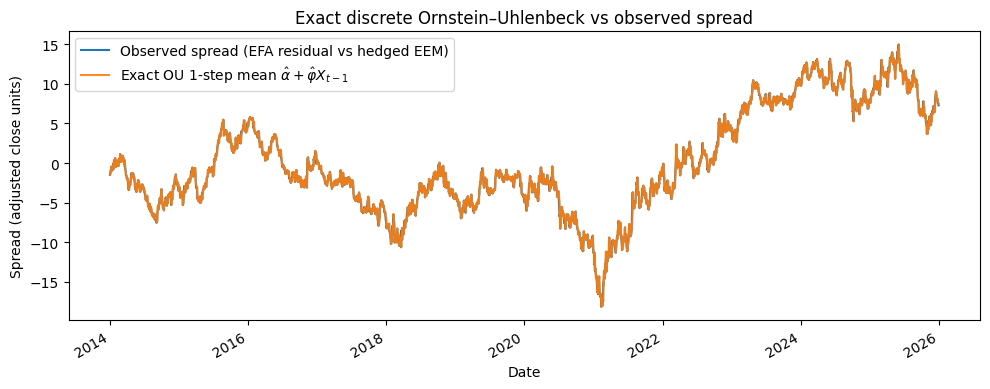

In [9]:
# Visualize the exact discrete OU fit: conditional mean E[X_t | X_{t-1}] = α̂ + φ̂ X_{t-1} (same as θ̂(1-φ̂) + φ̂ X_{t-1}).
spread_obs = spread_frame["spread"].dropna()
phi_hat = ou_exact["phi"]
alpha_hat = ou_exact["ar1_intercept"]
if np.isfinite(phi_hat) and np.isfinite(alpha_hat) and 0.0 < phi_hat < 1.0:
    spread_ou_mean = alpha_hat + phi_hat * spread_obs.shift(1)  # One-step OU/AR(1) prediction aligned on spread_obs index.
else:
    spread_ou_mean = pd.Series(np.nan, index=spread_obs.index)

fig_ou, ax_ou = plt.subplots(figsize=(10, 4))
spread_obs.plot(ax=ax_ou, label=f"Observed spread ({asset_a} residual vs hedged {asset_b})", color="C0")
spread_ou_mean.plot(ax=ax_ou, label=r"Exact OU 1-step mean $\hat{\alpha}+\hat{\varphi}X_{t-1}$", color="C1", alpha=0.9)
ax_ou.set_title("Exact discrete Ornstein–Uhlenbeck vs observed spread")
ax_ou.set_xlabel("Date")
ax_ou.set_ylabel("Spread (adjusted close units)")
ax_ou.legend(loc="best")
plt.tight_layout()
plt.show()

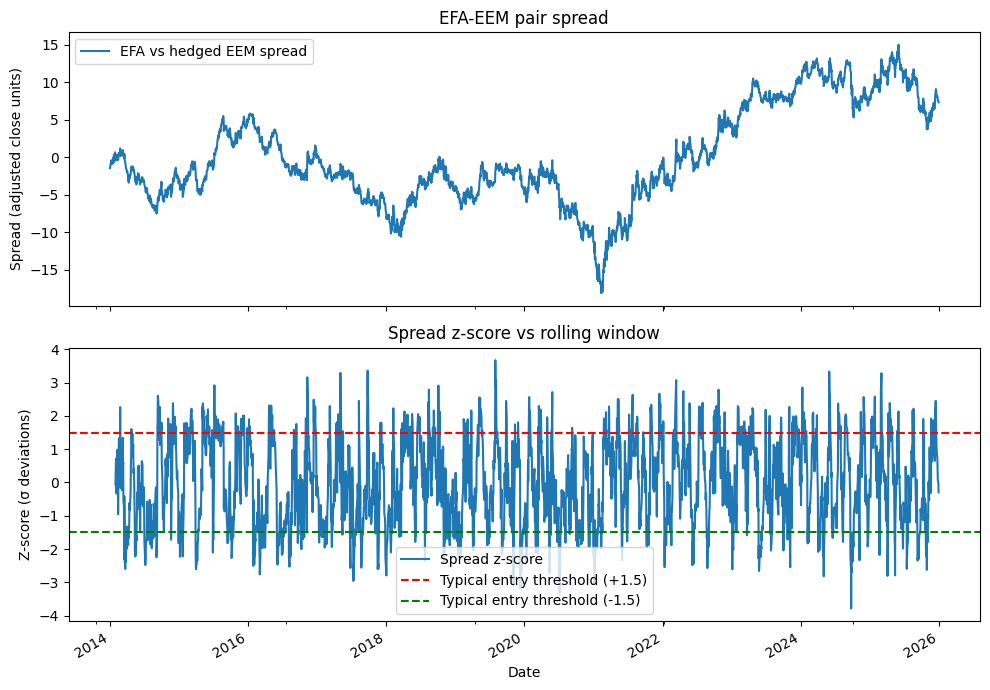

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
spread_frame["spread"].plot(ax=axes[0], title=f"{asset_a}-{asset_b} pair spread", label=f"{asset_a} vs hedged {asset_b} spread")
spread_zscore.plot(ax=axes[1], title="Spread z-score vs rolling window", label="Spread z-score")
axes[1].axhline(1.5, color="red", linestyle="--", label="Typical entry threshold (+1.5)")
axes[1].axhline(-1.5, color="green", linestyle="--", label="Typical entry threshold (-1.5)")
axes[0].set_ylabel("Spread (adjusted close units)")
axes[0].legend(loc="best")
axes[1].set_ylabel("Z-score (σ deviations)")
axes[1].set_xlabel("Date")
axes[1].legend(loc="best")
plt.tight_layout()
plt.show()


## Step 4 - Infer hidden market regimes

The HMM does not directly tell us labels such as `bull` or `crisis`.

Instead, it finds latent states that explain patterns in returns and volatility. We interpret those states after estimation by looking at their average behavior.

In [11]:
regime_features = build_regime_features(benchmark_returns, benchmark_realized_vol)
hmm_model = fit_hmm_regime_model(regime_features)
regimes = infer_regimes(hmm_model, regime_features)
regime_summary = summarize_regimes(regime_features, regimes)

regime_summary


returns                 realized_volatility                  \
            mean       std count                mean       std count   
regime                                                                 
0       0.000866  0.005373  1408            0.086501  0.020181  1408   
1       0.000278  0.010578  1249            0.161927  0.034068  1249   
2      -0.000033  0.023033   339            0.334244  0.159742   339   

        momentum                  
            mean       std count  
regime                            
0       0.001241  0.000910  1408  
1       0.000097  0.001789  1249  
2      -0.001009  0.004405   339

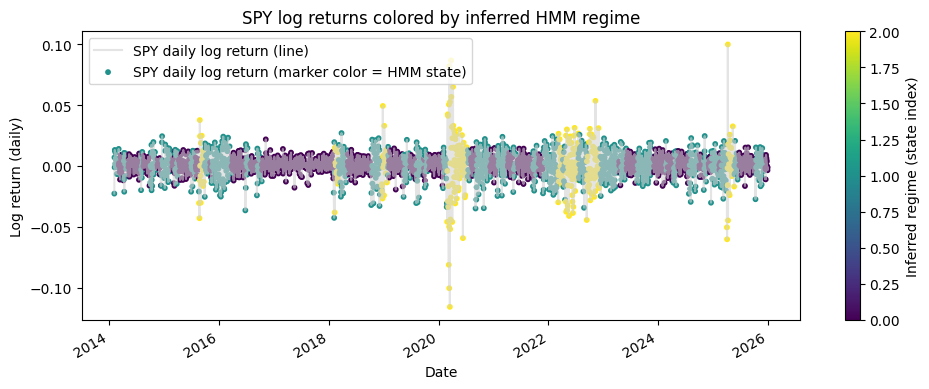

In [12]:
regime_plot_frame = pd.DataFrame({"returns": benchmark_returns.reindex(regimes.index), "regime": regimes})

fig, ax = plt.subplots(figsize=(10, 4))
regime_plot_frame["returns"].plot(ax=ax, color="lightgray", alpha=0.6, label="SPY daily log return (line)")  # Plot the raw return series in the background.
sc_reg = ax.scatter(
    regime_plot_frame.index,
    regime_plot_frame["returns"],
    c=regime_plot_frame["regime"],
    cmap="viridis",
    s=10,
    label="SPY daily log return (marker color = HMM state)",
)
ax.set_title("SPY log returns colored by inferred HMM regime")
ax.set_xlabel("Date")
ax.set_ylabel("Log return (daily)")
ax.legend(loc="best")
fig.colorbar(sc_reg, ax=ax, label="Inferred regime (state index)")
plt.tight_layout()
plt.show()


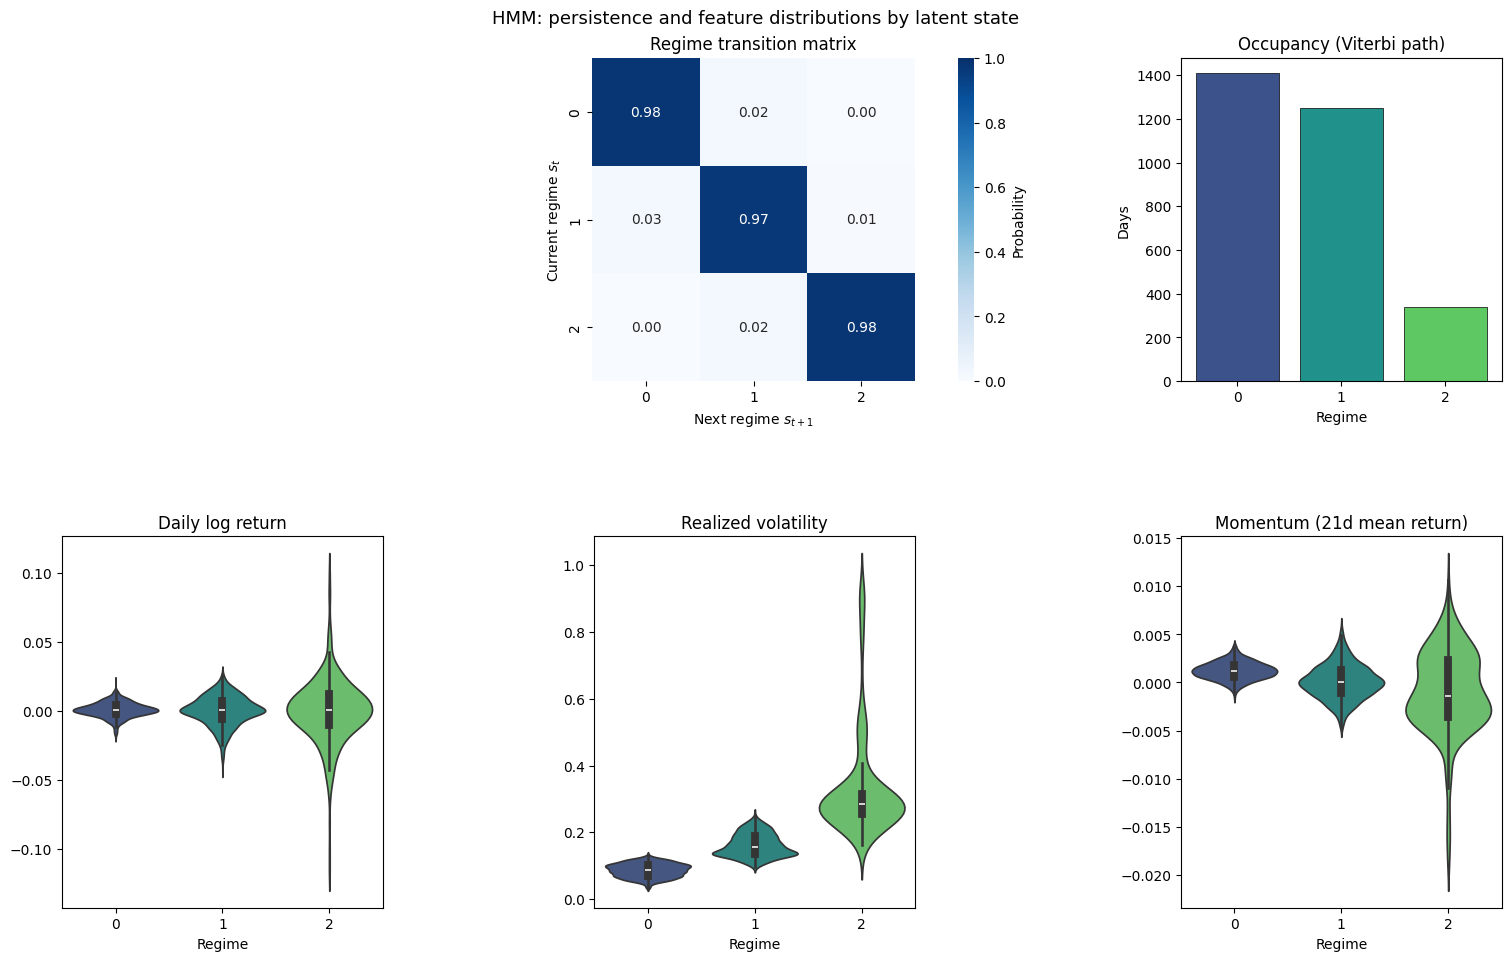

In [13]:
import seaborn as sns

viz_df = regime_features.copy()
viz_df["regime"] = regimes.astype(str)
n_states = hmm_model.n_components
order = [str(i) for i in range(n_states)]

fig = plt.figure(figsize=(15, 9.5), layout="constrained")
gs = fig.add_gridspec(2, 3, height_ratios=[1.0, 1.15], hspace=0.18, wspace=0.18)
pal = sns.color_palette("viridis", n_states)

ax_tm = fig.add_subplot(gs[0, :2])
sns.heatmap(
    hmm_model.transmat_,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1,
    square=True,
    ax=ax_tm,
    xticklabels=order,
    yticklabels=order,
    cbar_kws={"label": "Probability"},
)
ax_tm.set_xlabel(r"Next regime $s_{t+1}$")
ax_tm.set_ylabel(r"Current regime $s_t$")
ax_tm.set_title("Regime transition matrix")

ax_occ = fig.add_subplot(gs[0, 2])
occ = regimes.value_counts().reindex(range(n_states), fill_value=0)
ax_occ.bar(order, occ.values, color=pal, edgecolor="black", linewidth=0.5)
ax_occ.set_xlabel("Regime")
ax_occ.set_ylabel("Days")
ax_occ.set_title("Occupancy (Viterbi path)")

panels = [
    ("returns", "Daily log return"),
    ("realized_volatility", "Realized volatility"),
    ("momentum", "Momentum (21d mean return)"),
]
for col, (key, title) in enumerate(panels):
    ax = fig.add_subplot(gs[1, col])
    sns.violinplot(
        data=viz_df,
        x="regime",
        y=key,
        order=order,
        hue="regime",
        hue_order=order,
        inner="box",
        palette=pal,
        ax=ax,
        legend=False,
        dodge=False,
    )
    ax.set_title(title)
    ax.set_xlabel("Regime")
    ax.set_ylabel("")

fig.suptitle("HMM: persistence and feature distributions by latent state", fontsize=13)
plt.show()